# 05 · CSV único, persistencia y confirmaciones

[Índice](00_indice_y_recorrido.ipynb) · [Anterior](04_sensores_json_y_pantalla.ipynb) · [Siguiente](06_hardware_y_medicion.ipynb)

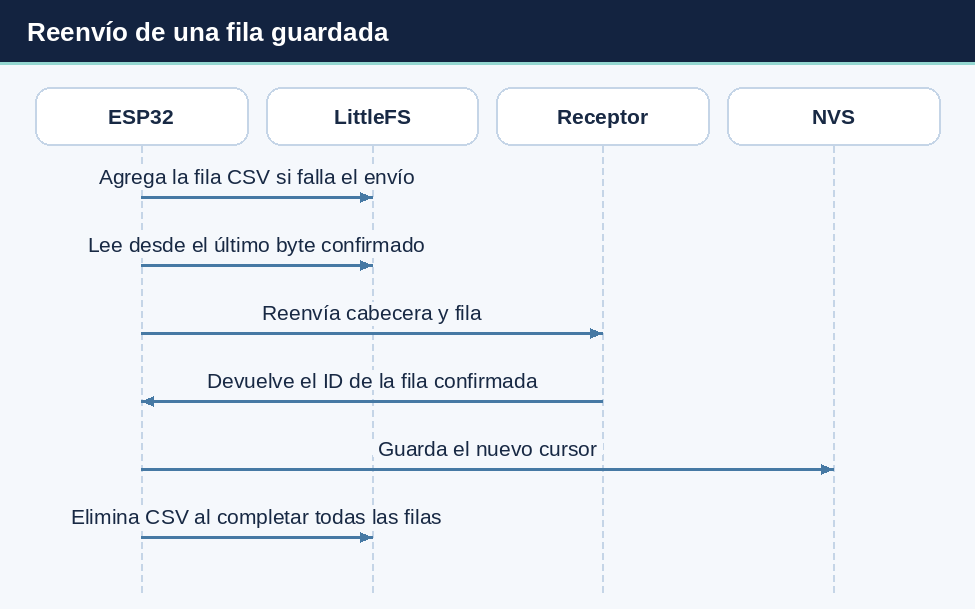

## Dos almacenamientos distintos

LittleFS guarda texto en `/pending.csv`. Preferences guarda el cursor en NVS, espacio `csv-queue`,
clave `offset`. NVS no contiene las lecturas. El offset es una posición en bytes, no un contador
de muestras. En cada reinicio se recupera para saltar las filas que ya se confirmaron.

El archivo es una cola de solo anexado durante la desconexión. No se reescribe entero después de
cada ACK: las filas confirmadas siguen físicamente dentro hasta que todas estén confirmadas.
Esto evita copiar repetidamente el historial; a cambio, ese espacio no se recupera de inmediato.

### Columnas del CSV

| Columna | Ejemplo | Uso |
|---|---|---|
| id | `0000000100000001` | Correlacionar fila con ACK; no es el ID del dispositivo. |
| device_id | `ESP32_S3_0001` | Debe coincidir con el dispositivo del topic. |
| timestamp | `2026-11-20T14:30:00-06:00` | Fecha capturada al tomar la lectura; vacía si faltaba hora. |
| temperature | `25.00` | Temperatura °C, o vacío si inválida. |
| humidity | `67.50` | Humedad %RH, o vacío si inválida. |
| gas | `89.20` | Ppm estimadas, o vacío. |
| calibrate | `false` | Estado de calibración del cálculo actual. |

La cabecera debe estar en ese orden. El firmware concatena campos simples, sin comillas CSV;
los campos que genera no contienen comas internas. Cambiar IDs a texto con comas requeriría
implementar escapado CSV en el productor.

```csv
id,device_id,timestamp,temperature,humidity,gas,calibrate
0000000100000001,ESP32_S3_0001,2026-11-20T14:30:00-06:00,25.00,67.50,89.20,false
0000000100000002,ESP32_S3_0001,2026-11-20T14:30:02-06:00,25.10,67.00,90.40,false
0000000100000003,ESP32_S3_0001,2026-11-20T14:30:04-06:00,25.10,67.00,,false
0000000100000004,ESP32_S3_0001,,,,,false
```

## `saveMeasurementCsv`


**Parámetros:** timestamp por referencia constante y tres mediciones `float`. **Retorno:** `void`.

Primero comprueba `LittleFS.totalBytes()-LittleFS.usedBytes()` contra 8192. Si no hay margen,
registra el fallo y descarta esa nueva lectura. No hay otro respaldo si falla LittleFS.
`exists(CSV_PATH)` permite detectar un archivo nuevo. Antes de crearlo restablece NVS offset a 0;
solo continúa si `putULong` devolvió el número de bytes esperado. Esto evita usar un cursor antiguo
contra un archivo nuevo.

`esp_random()` se llama dos veces. `snprintf(recordId,sizeof(recordId),"%08lx%08lx",...)` concatena
dos valores hexadecimales de al menos ocho posiciones con ceros a la izquierda. El resultado
es un ID aleatorio de 16 caracteres en esta plataforma; no es una secuencia ni una prueba de
unicidad absoluta. `recordId[24]` deja espacio suficiente, incluido el terminador cero.

Construye una fila con dos decimales y `false` literal. Abre con modo `"a"` (append): crea si no
existe y agrega al final si existe. Si el tamaño es 0 escribe primero la cabecera. `print()` devuelve
bytes escritos; se comparan con la longitud esperada y se imprime un error si hubo escritura parcial.
Finalmente cierra el archivo. La comprobación no revierte una escritura parcial ya realizada.

```cpp
void saveMeasurementCsv(const String &timestamp, float temperature, float humidity, float gasPpm) {
    if (LittleFS.totalBytes() - LittleFS.usedBytes() < MIN_FREE_STORAGE_BYTES) {
        Serial.println("ERROR: almacenamiento lleno; lectura no guardada");
        return;
    }

    const bool isNewFile = !LittleFS.exists(CSV_PATH);
    if (isNewFile) {
        if (queuePreferences.putULong("offset", 0) != sizeof(uint32_t)) {
            Serial.println("ERROR: no se pudo reiniciar el estado del CSV");
            return;
        }
        confirmedCsvOffset = 0;
    }

    char recordId[24];
    snprintf(recordId, sizeof(recordId), "%08lx%08lx", (unsigned long)esp_random(),
             (unsigned long)esp_random());
    const String row = String(recordId) + "," + DEVICE_ID + "," + timestamp + "," +
                       formatCsvNumber(temperature) + "," + formatCsvNumber(humidity) + "," +
                       formatCsvNumber(gasPpm) + ",false\n";
    File file = LittleFS.open(CSV_PATH, "a");
    if (!file) {
        Serial.println("ERROR: no se pudo abrir el CSV");
        return;
    }

    const bool headerWritten = file.size() != 0 || file.print(CSV_HEADER) == strlen(CSV_HEADER);
    if (!headerWritten || file.print(row) != row.length()) {
        Serial.println("ERROR: escritura incompleta del CSV");
    }
    file.close();
}
```

## `publishPendingCsv`


**Parámetros:** ninguno. **Retorno:** `void`. Revisa la cola cada 5000 ms si MQTT está conectado.

Abre el único archivo en modo lectura. Si no existe, no hay nada que reenviar. Si el cursor
confirmado alcanzó o superó `size()`, cierra el archivo e intenta `remove(CSV_PATH)`. Solo si
el borrado tuvo éxito limpia cursor RAM e ID pendiente e informa por Serial. El cursor NVS no se
pone en cero en ese punto: se restablece antes de crear el siguiente archivo nuevo.

Si `confirmedCsvOffset==0`, lee y omite la primera línea, que debe ser la cabecera. En otro caso
usa `seek(confirmedCsvOffset)`. `readStringUntil('\n')` devuelve la fila sin el delimitador de
salto de línea, que sí consume del archivo. `indexOf(',')` encuentra el final del ID; `substring`
extrae ese ID. La validación del firmware es mínima: comprueba que haya una coma después de un ID.
Python valida las siete columnas.

`file.position()` da el byte siguiente después de la fila leída; se conserva en `pendingCsvEndOffset`.
Envía `CSV_HEADER + row + "\n"`, es decir, un CSV pequeño de una fila. No carga todo el archivo en RAM.
Hasta recibir ACK no cambia el cursor confirmado y vuelve a leer la misma fila en el próximo intento.
`pendingRecordId` identifica qué confirmación aceptar.

El borrado sucede en una revisión posterior al último ACK, hasta unos 5 s después según la ejecución.
Si se agregaron filas antes de esa revisión, el tamaño habrá crecido y esas filas también deberán
confirmarse. El método no depende del nombre de un archivo por fila.

```cpp
void publishPendingCsv() {
    if (!mqttClient.connected() || millis() - lastReplayAt < CSV_RETRY_INTERVAL_MS) {
        return;
    }
    lastReplayAt = millis();

    File file = LittleFS.open(CSV_PATH, "r");
    if (!file) {
        return;
    }

    // El archivo se borra al confirmar todas sus filas; no se reescribe por cada ACK.
    if (confirmedCsvOffset >= file.size()) {
        file.close();
        if (LittleFS.remove(CSV_PATH)) {
            confirmedCsvOffset = 0;
            pendingRecordId = "";
            Serial.println("CSV confirmado y eliminado");
        }
        return;
    }

    if (confirmedCsvOffset == 0) {
        file.readStringUntil('\n'); // Omitir la cabecera una sola vez.
    } else if (!file.seek(confirmedCsvOffset)) {
        Serial.println("ERROR: no se pudo leer la posicion del CSV");
        return;
    }

    const String row = file.readStringUntil('\n');
    const int separator = row.indexOf(',');
    if (separator <= 0) {
        Serial.println("ERROR: fila CSV incompleta; archivo conservado");
        return;
    }

    pendingRecordId = row.substring(0, separator);
    pendingCsvEndOffset = file.position();
    const String payload = String(CSV_HEADER) + row + "\n";
    mqttClient.publish(rawTopic.c_str(), payload.c_str());
}
```

## API de archivos y NVS utilizada

| Método | Parámetros/argumentos | Retorno o efecto |
|---|---|---|
| `LittleFS.begin(false)` | No formatear al fallar | bool de montaje. |
| `LittleFS.open(path,mode)` | Ruta y `"r"` / `"a"` | Objeto `File`, evaluable como válido/inválido. |
| `LittleFS.exists(path)` | Ruta del CSV | bool de existencia. |
| `LittleFS.totalBytes()/usedBytes()` | Sin argumentos | Capacidad/uso del sistema de archivos en bytes. |
| `LittleFS.remove(path)` | Ruta | bool; elimina archivo si puede. |
| `File.size()` | Sin argumentos | Tamaño en bytes. |
| `File.print(text)` | Cadena/cabecera | Cantidad escrita, no confirmación MQTT. |
| `File.readStringUntil(delimiter)` | Carácter `\n` | Texto anterior al delimitador o fin/timeout. |
| `File.seek(offset)` | Posición absoluta en este uso | bool de reposicionamiento. |
| `File.position()` | Sin argumentos | Posición actual en bytes. |
| `File.close()` | Sin argumentos | Libera/cierra el acceso. |
| `Preferences.begin(namespace,readOnly)` | `"csv-queue", false` | Abre NVS para escribir, devuelve bool. |
| `Preferences.getULong(key,default)` | `"offset", 0` | Cursor persistido o predeterminado. |
| `Preferences.putULong(key,value)` | Clave y byte final de fila | Número de bytes almacenados; 4 esperado. |

## Recorrido manual con dos filas

Supón cabecera de H bytes, primera fila de A bytes y segunda de B bytes.
Al inicio offset=0. Se omite cabecera, se envía fila 1 y se espera su ID. Al confirmar se persiste
H+A. El siguiente envío se posiciona en H+A y envía fila 2. Al confirmar persiste H+A+B. La revisión
siguiente ve offset==tamaño y elimina el archivo. Si se reinicia después del primer ACK, recupera
H+A y continúa con la segunda fila.

### Casos que hay que distinguir

- Si Python está apagado pero el broker funciona, las filas históricas quedan pendientes; las
  lecturas actuales pueden seguir llegando directamente a `/tratado`.
- Si Python publicó el JSON pero el ACK se pierde, se repite la fila: puede haber duplicados.
- Si falla guardar NVS, el cursor no avanza y el archivo se conserva.
- Si se corta alimentación a mitad de escritura, puede quedar una fila incompleta. El conversor
  la rechaza; el código no la repara ni la salta automáticamente y puede detener el progreso.
- Un archivo que contiene solo cabecera tampoco tiene una fila procesable; no se vacía automáticamente.
- Los archivos `/queue/*.csv` de la versión anterior no se migran ni borran con esta implementación.
- `uploadfs` puede reemplazar LittleFS sin borrar NVS. No debe usarse como mecanismo para actualizar
  una cola activa: el cursor externo puede quedar desalineado si se reemplaza el CSV manualmente.

Estas son propiedades del código actual; no se afirma entrega exactamente una vez ni recuperación
atómica ante cualquier corte eléctrico. El ACK identifica el registro, pero no incorpora autenticación
propia; la autorización de los topics depende del broker.

In [ ]:
# Ejercicio sin hardware: los offsets cuentan bytes, no líneas.
header = "id,device_id,timestamp,temperature,humidity,gas,calibrate\n"
rows = [
    "a,ESP32_S3_0001,,25.00,60.00,90.00,false\n",
    "b,ESP32_S3_0001,,25.10,60.20,91.00,false\n",
]
data = (header + "".join(rows)).encode("utf-8")
first_confirmed_offset = len((header + rows[0]).encode("utf-8"))
assert data[first_confirmed_offset:].decode("utf-8") == rows[1]
print("Cursor tras primer ACK:", first_confirmed_offset)
print("Siguiente fila:", data[first_confirmed_offset:].decode("utf-8").strip())

## Contrato que observa el dispositivo

Al reenviar, el ESP32 publica la cabecera CSV y una fila. El lado receptor lee el ID y devuelve ese mismo texto en el tema de confirmación. El firmware compara todos los bytes del ID con el pendiente y actualiza el cursor solo si obtiene el tamaño esperado de la escritura en NVS. Retener el archivo hasta confirmar todas las filas evita reescribir gran parte de la flash por cada confirmación.

La [muestra CSV](pending.example.csv) reúne lecturas completas y lecturas con campos vacíos. Compara los índices de byte del ejercicio con lo que informa Serial en la placa.

[Índice](00_indice_y_recorrido.ipynb) · [Anterior](04_sensores_json_y_pantalla.ipynb) · [Siguiente](06_hardware_y_medicion.ipynb)